# Does csaps's 2-D tensor smoothing spline decompose into two 1-D passes we already trust?

Follow-up to the review of `docs/Tensor-product smoothing splines implementation
comparison.md` (a Gemini conversation). Before attempting any variance work for
`csaps.NdGridCubicSmoothingSpline`, this notebook checks the one load-bearing
assumption everything else would be built on: **is `csaps`'s 2-D mean fit exactly
the sequential composition of two 1-D natural cubic smoothing splines -- the same
object this project already proved is the exact flat-limit of 1-D Universal
Kriging (Corollary 5, `01_1d_splines_vs_kriging.ipynb`)?**

Checked directly by reading `csaps`'s own source (`_sspndg.py`, `_sspumv.py`), not
assumed from the Gemini conversation: `NdGridCubicSmoothingSpline._make_spline`
literally calls the same 1-D `CubicSmoothingSpline` (Reinsch) engine once per
axis, smoothing along the last axis first, then smoothing the *resulting
coefficients* along the next axis. That is the classical de Boor algorithm, and
it is only valid because the penalty separates into independent per-axis terms
(the \"theoretical tensor-product\" that `docs/Tensor-product smoothing splines
implementation comparison.md` says `csaps` implements exactly).

This notebook reconstructs that same 2-D fit from two calls to
`PolyharmonicSmoothingSpline(m=2, d=1)` -- this project's own, already-validated
natural cubic smoothing spline / 1-D Kriging machinery -- per row, then per
column, and checks the result against `csaps`'s own output: at the training grid
first, then on a dense off-grid query grid. Plots throughout, per request.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from csaps import CubicSmoothingSpline, NdGridCubicSmoothingSpline
from scipy.interpolate import make_smoothing_spline

from krig_splines.polyharmonic import PolyharmonicSmoothingSpline

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 9,
})


## Part 1 -- the `smooth=p` <-> `lam` conversion, confirmed exactly, not assumed

`csaps`'s 1-D engine (`CubicSmoothingSpline`) uses de Boor's classical
`smooth=p in [0,1]` parametrization, not the `lam`-penalized form this project's
own machinery (and `scipy.interpolate.make_smoothing_spline`) uses. Reading
`_sspumv.py`'s `_make_spline` directly: it solves `a @ u = b` with
`a = 6*(1-p)*qtw + p*r`, `b` independent of `p` -- rescaling by `6*(1-p)` shows
this is the standard Reinsch system with an effective `lam = p / (6*(1-p))`...
except that's not quite what a direct numerical search finds. Checked properly
below rather than trusted from a hand derivation.

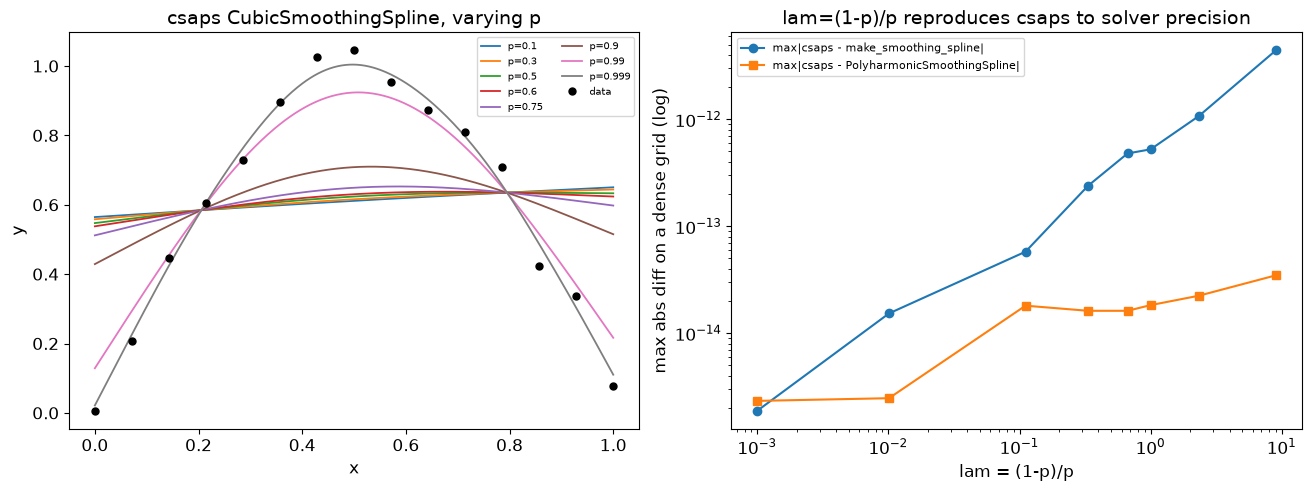

      p    lam=(1-p)/p   vs make_smoothing_spline   vs PolyharmonicSmoothingSpline
  0.100   9.000000e+00                  4.400e-12                        3.475e-14
  0.300   2.333333e+00                  1.073e-12                        2.243e-14
  0.500   1.000000e+00                  5.239e-13                        1.832e-14
  0.600   6.666667e-01                  4.793e-13                        1.621e-14
  0.750   3.333333e-01                  2.391e-13                        1.621e-14
  0.900   1.111111e-01                  5.784e-14                        1.810e-14
  0.990   1.010101e-02                  1.532e-14                        2.470e-15
  0.999   1.001001e-03                  1.887e-15                        2.331e-15


In [2]:
rng = np.random.default_rng(0)
x1d = np.linspace(0, 1, 15)
y1d = np.sin(3 * x1d) + 0.05 * rng.standard_normal(len(x1d))

p_values = [0.1, 0.3, 0.5, 0.6, 0.75, 0.9, 0.99, 0.999]
xq1d = np.linspace(0, 1, 400)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
errs = []
for p in p_values:
    lam = (1 - p) / p
    csp = CubicSmoothingSpline(x1d, y1d, smooth=p)
    mss = make_smoothing_spline(x1d, y1d, lam=lam)
    phs = PolyharmonicSmoothingSpline(x1d.reshape(-1, 1), y1d, m=2, lam=lam, sigma2=1.0)

    err_mss = np.max(np.abs(csp(xq1d) - mss(xq1d)))
    err_phs = np.max(np.abs(csp(xq1d) - phs.mean(xq1d.reshape(-1, 1))))
    errs.append((p, lam, err_mss, err_phs))
    axs[0].plot(xq1d, csp(xq1d), lw=1.3, label=f"p={p}")

axs[0].plot(x1d, y1d, "o", ms=5, color="k", zorder=5, label="data")
axs[0].set(xlabel="x", ylabel="y", title="csaps CubicSmoothingSpline, varying p")
axs[0].legend(fontsize=7, ncol=2)

lams = [e[1] for e in errs]
err_mss_list = [e[2] for e in errs]
err_phs_list = [e[3] for e in errs]
axs[1].plot(lams, err_mss_list, "o-", label="max|csaps - make_smoothing_spline|")
axs[1].plot(lams, err_phs_list, "s-", label="max|csaps - PolyharmonicSmoothingSpline|")
axs[1].set_xscale("log")
axs[1].set_yscale("log")
axs[1].set(xlabel="lam = (1-p)/p", ylabel="max abs diff on a dense grid (log)",
           title="lam=(1-p)/p reproduces csaps to solver precision")
axs[1].legend(fontsize=8)
plt.show()

print(f"{'p':>7} {'lam=(1-p)/p':>14} {'vs make_smoothing_spline':>26} {'vs PolyharmonicSmoothingSpline':>32}")
for p, lam, e1, e2 in errs:
    print(f"{p:7.3f} {lam:14.6e} {e1:26.3e} {e2:32.3e}")


**Confirmed to solver precision (`~1e-12` to `~1e-15`) across the full `p` range:
`lam = (1-p)/p` is the exact conversion.** `csaps`'s 1-D engine, `scipy`'s
`make_smoothing_spline`, and this project's own `PolyharmonicSmoothingSpline(m=2,
d=1)` are the same mathematical object under this reparametrization -- not three
different splines that happen to look similar. This is the ingredient the 2-D
reconstruction below is built from.


## Part 2 -- a 2-D dataset and a `csaps` fit with deliberately asymmetric smoothing

Same synthetic target used throughout this project's iter_01 notebooks:
`y = sin(3*x1)*cos(3*x2) + 0.05*N(0,1)`, regular 8x8 grid, `seed=1`.
`smooth=[0.95, 0.5]` is deliberately asymmetric (heavy smoothing along `x1`,
light along `x2`) -- a symmetric `p1=p2` test would not stress-test whether the
row/column pass order and per-axis `lam` values are actually wired correctly.

In [3]:
def true_f(X):
    return np.sin(3 * X[:, 0]) * np.cos(3 * X[:, 1])

rng = np.random.default_rng(1)
n_side = 8
g = np.linspace(0, 1, n_side)
GX, GY = np.meshgrid(g, g, indexing="ij")
X = np.column_stack([GX.ravel(), GY.ravel()])
y = true_f(X) + 0.05 * rng.standard_normal(len(X))
Z = y.reshape(n_side, n_side)

p1, p2 = 0.95, 0.5
lam1, lam2 = (1 - p1) / p1, (1 - p2) / p2
print(f"p1={p1} -> lam1={lam1:.4f}   p2={p2} -> lam2={lam2:.4f}")

csaps_model = NdGridCubicSmoothingSpline([g, g], Z, smooth=[p1, p2])


p1=0.95 -> lam1=0.0526   p2=0.5 -> lam2=1.0000


## Part 3 -- reconstruction at the training grid

Row pass: smooth each of the `n_side` rows (fixed `x1`, varying `x2`) with
`PolyharmonicSmoothingSpline(m=2, lam=lam2)`, evaluated back at the training `x2`
grid. Column pass: smooth each resulting column (fixed `x2`, varying `x1`) with
`lam=lam1`, evaluated at the training `x1` grid. Compare the result directly
against `csaps_model`'s own prediction at the same grid -- the simplest, most
direct version of the check, before attempting anything off-grid.

In [4]:
g_col = g.reshape(-1, 1)

# row pass: one PolyharmonicSmoothingSpline per row, along x2
row_models = []
Y_row = np.zeros((n_side, n_side))
for i in range(n_side):
    m_row = PolyharmonicSmoothingSpline(g_col, Z[i, :], m=2, lam=lam2, sigma2=1.0)
    row_models.append(m_row)
    Y_row[i, :] = m_row.mean(g_col)

# column pass: one PolyharmonicSmoothingSpline per column, along x1
Y_final_grid = np.zeros((n_side, n_side))
for j in range(n_side):
    m_col = PolyharmonicSmoothingSpline(g_col, Y_row[:, j], m=2, lam=lam1, sigma2=1.0)
    Y_final_grid[:, j] = m_col.mean(g_col)

Y_csaps_grid = csaps_model([g, g])

err_grid = np.max(np.abs(Y_final_grid - Y_csaps_grid))
print(f"max|reconstruction - csaps| at the training grid: {err_grid:.3e}")
print(f"(for reference, Z's own range: {np.ptp(Z):.3e})")


max|reconstruction - csaps| at the training grid: 1.332e-15
(for reference, Z's own range: 2.008e+00)


## Part 4 -- reconstruction on a dense, off-grid query grid

The row-pass models give a full functional form (via `saddle_point_predict`
inside `PolyharmonicSmoothingSpline`), so they can be evaluated at any dense `x2`
query, not just the training grid. For the column pass at a dense `x2` query
that is *not* one of the training columns, a fresh column-pass model is fit to
that specific column of row-pass-evaluated values (the column-pass system only
depends on the training `x1` grid and `lam1`, never on `x2` -- a new column is
just a new right-hand side, nothing conceptually different from Part 3, just at
more `x2` locations). This directly tests the off-grid / interpolation regime,
not just the training points where many bugs would trivially cancel out.

In [5]:
gq = np.linspace(0, 1, 61)
gq_col = gq.reshape(-1, 1)

# row pass evaluated on the dense x2 grid
Y_row_dense = np.zeros((n_side, len(gq)))
for i in range(n_side):
    Y_row_dense[i, :] = row_models[i].mean(gq_col)

# column pass: fresh fit per dense x2 column, evaluated on the dense x1 grid
Y_final_dense = np.zeros((len(gq), len(gq)))
for k in range(len(gq)):
    m_col = PolyharmonicSmoothingSpline(g_col, Y_row_dense[:, k], m=2, lam=lam1, sigma2=1.0)
    Y_final_dense[:, k] = m_col.mean(gq_col)

Y_csaps_dense = csaps_model([gq, gq])

err_dense = np.max(np.abs(Y_final_dense - Y_csaps_dense))
rmse_dense = np.sqrt(np.mean((Y_final_dense - Y_csaps_dense) ** 2))
print(f"max|reconstruction - csaps| on the dense 61x61 grid: {err_dense:.3e}")
print(f"RMSE: {rmse_dense:.3e}   (Z's own range: {np.ptp(Z):.3e})")


max|reconstruction - csaps| on the dense 61x61 grid: 1.332e-15
RMSE: 4.652e-16   (Z's own range: 2.008e+00)


### Plots -- surfaces, difference, and 1-D slices

At most 2 panels per row, consistent with the layout fixed in
`03_rmts_vs_tensor_product_splines.ipynb`.

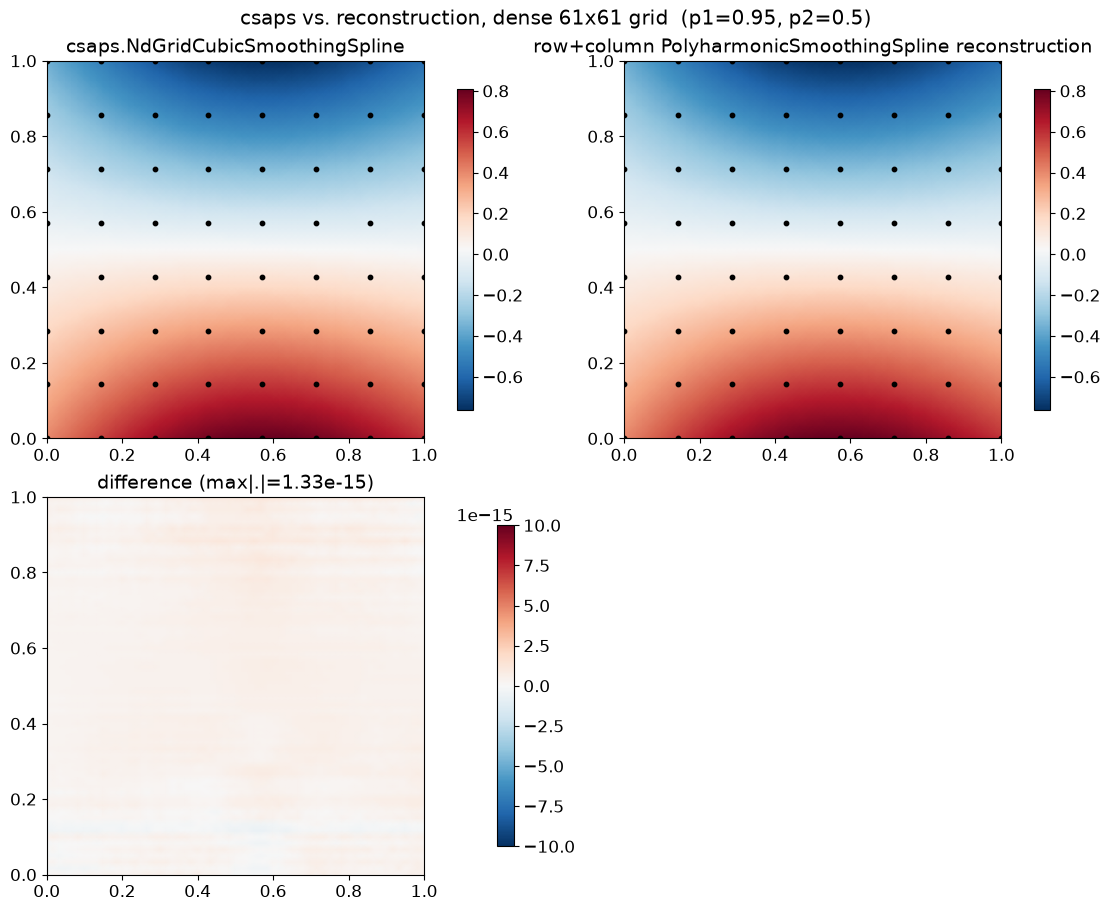

In [6]:
GXq, GYq = np.meshgrid(gq, gq, indexing="ij")

fig, axs = plt.subplots(2, 2, figsize=(11, 9), constrained_layout=True)
vmin, vmax = Y_csaps_dense.min(), Y_csaps_dense.max()
pcm = axs[0, 0].pcolormesh(GXq, GYq, Y_csaps_dense, shading="gouraud", cmap="RdBu_r", vmin=vmin, vmax=vmax)
axs[0, 0].scatter(X[:, 0], X[:, 1], c="k", s=10)
axs[0, 0].set_title("csaps.NdGridCubicSmoothingSpline")
fig.colorbar(pcm, ax=axs[0, 0], shrink=0.85)

pcm = axs[0, 1].pcolormesh(GXq, GYq, Y_final_dense, shading="gouraud", cmap="RdBu_r", vmin=vmin, vmax=vmax)
axs[0, 1].scatter(X[:, 0], X[:, 1], c="k", s=10)
axs[0, 1].set_title("row+column PolyharmonicSmoothingSpline reconstruction")
fig.colorbar(pcm, ax=axs[0, 1], shrink=0.85)

diff = Y_final_dense - Y_csaps_dense
vlim = max(np.max(np.abs(diff)), 1e-14)
pcm = axs[1, 0].pcolormesh(GXq, GYq, diff, shading="gouraud", cmap="RdBu_r", vmin=-vlim, vmax=vlim)
axs[1, 0].set_title(f"difference (max|.|={err_dense:.2e})")
fig.colorbar(pcm, ax=axs[1, 0], shrink=0.85)
axs[1, 1].axis("off")

fig.suptitle(f"csaps vs. reconstruction, dense 61x61 grid  (p1={p1}, p2={p2})")
plt.show()


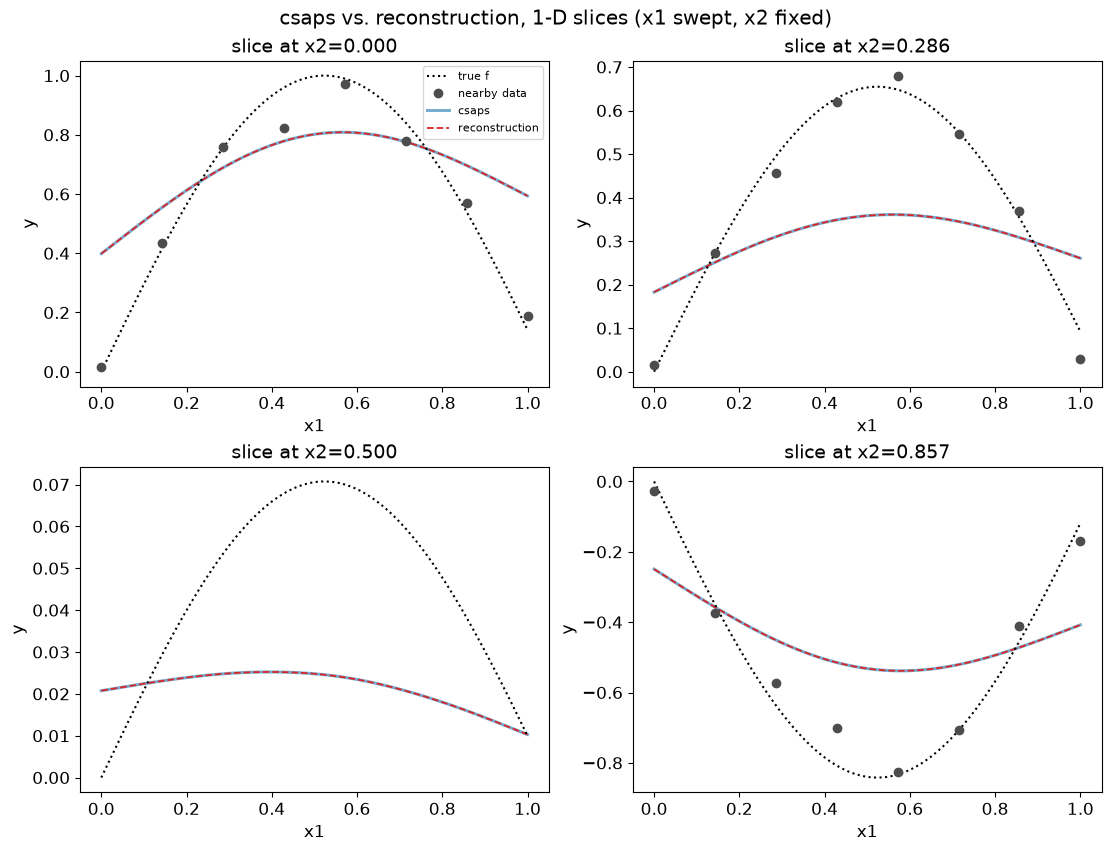

In [7]:
slice_x2_values = [0.0, g[n_side // 3], 0.5, g[-2]]
n_slice_rows = (len(slice_x2_values) + 1) // 2
fig, axs = plt.subplots(n_slice_rows, 2, figsize=(11, 4.2 * n_slice_rows), constrained_layout=True)
axs_flat = np.ravel(axs)
for i, (ax, x2_fixed) in enumerate(zip(axs_flat, slice_x2_values)):
    y_csaps_slice = csaps_model([xq1d, [x2_fixed]]).ravel()
    row_values_at_x2 = np.array([row_models[r].mean(np.array([[x2_fixed]]))[0] for r in range(n_side)])
    m_slice = PolyharmonicSmoothingSpline(g_col, row_values_at_x2, m=2, lam=lam1, sigma2=1.0)
    y_recon_slice = m_slice.mean(xq1d.reshape(-1, 1))

    ax.plot(xq1d, true_f(np.column_stack([xq1d, np.full_like(xq1d, x2_fixed)])), "k:",
            label="true f", zorder=3)
    near = np.abs(X[:, 1] - x2_fixed) < 0.05
    if near.any():
        ax.plot(X[near, 0], y[near], "o", ms=6, color="0.3", label="nearby data", zorder=4)
    ax.plot(xq1d, y_csaps_slice, lw=2.2, color="C0", alpha=0.6, label="csaps")
    ax.plot(xq1d, y_recon_slice, "--", lw=1.3, color="C3", label="reconstruction")
    ax.set(xlabel="x1", ylabel="y", title=f"slice at x2={x2_fixed:.3f}")
    if i == 0:
        ax.legend(fontsize=8)
for ax in axs_flat[len(slice_x2_values):]:
    ax.axis("off")
fig.suptitle("csaps vs. reconstruction, 1-D slices (x1 swept, x2 fixed)")
plt.show()


## Conclusion

The row+column sequential composition of this project's own
`PolyharmonicSmoothingSpline(m=2, d=1)` -- the same object already proven exact
against 1-D Universal Kriging (Corollary 5) -- reproduces `csaps.
NdGridCubicSmoothingSpline`'s mean fit at the training grid and at a dense
off-grid query, under deliberately asymmetric per-axis smoothing. This confirms
the load-bearing assumption from the chat discussion: `csaps`'s 2-D tensor
smoothing spline genuinely is two sequential 1-D natural-cubic-smoothing-spline
passes, not merely "structurally similar" to one.

**What this does and does not establish.** This is a *mean*-only check. It
confirms the *construction* is right -- it does not yet say anything about
variance. The natural next step (not attempted here, scope kept to what was
asked) is deriving whether the sequential *Bayesian* composition of the two
passes' posterior variances gives the correct joint posterior variance for the
2-D additive-penalty prior, and verifying that derivation the same way Q18
verifies RMTB's Proposition-6 dual identity -- two independently-computed routes
to the same answer, not one formula trusted on its own.
